# Is week 1 a good proxy for a Netflix title's later viewing?

Netflix publishes two public views numbers for its new titles. The weekly Top 10 gives views for the first week a title is out. The What We Watched report gives views over the rest of the half-year. This notebook asks how well the first number predicts the second, where it breaks, and how noisy it is.

A view is hours watched divided by runtime. The public week runs Monday to Sunday, so how many days a title had in its first week depends on its release day. Netflix's own all-time Most Popular lists count a title's first 91 days. Netflix has daily data and can count from the hour a title goes live. This study uses the public numbers only.

All data is public and comes from Netflix. Run `get_data.sh` and then `python src/prep.py` to rebuild `data/titles.csv` from the raw files.

In [1]:
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy.stats import spearmanr

sys.path.append("src")
import charts
import stats

pd.set_option("display.width", 120)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")
charts.apply_chart_style()

DATES = ["release", "window_end", "wk1_end", "first_top10"]
titles = pd.read_csv("data/titles.csv", parse_dates=DATES)
SEGMENTS = ["Film / English", "Film / Non-English", "TV / English", "TV / Non-English"]
COLORS = {
    "Film / English": "#2a78d6",
    "Film / Non-English": "#7fb3ec",
    "TV / English": "#d65a2a",
    "TV / Non-English": "#eba487",
}
results = {}
print(f"{len(titles):,} new releases, July 2024 to June 2026")

1,851 new releases, July 2024 to June 2026


## 1. Coverage

A title has a public week-1 number only if it made one of the four weekly global lists (English films, non-English films, English TV, non-English TV) in its release week. Live events and WWE library rows are listed episode by episode, so coverage is shown with and without them.

In [2]:
def coverage(table):
    """Share of titles with a week-1 number, and their share of all views."""
    in_week1 = table["status"] == "Top 10 in week 1"
    return {
        "titles": len(table),
        "with_week1": int(in_week1.sum()),
        "share_of_titles": in_week1.mean(),
        "share_of_views": table.loc[in_week1, "views"].sum() / table["views"].sum(),
    }


programs = titles[~titles["live"] & ~titles["wwe_library"]]
coverage_table = pd.DataFrame(
    {"All new releases": coverage(titles), "Without live and WWE library rows": coverage(programs)}
).T
results["coverage"] = coverage_table.to_dict(orient="index")
coverage_table.style.format(
    {
        "titles": "{:,.0f}",
        "with_week1": "{:,.0f}",
        "share_of_titles": "{:.1%}",
        "share_of_views": "{:.1%}",
    }
)

,titles,with_week1,share_of_titles,share_of_views
All new releases,"1,851",877,47.4%,88.1%
Without live and WWE library rows,"1,462",796,54.4%,89.1%


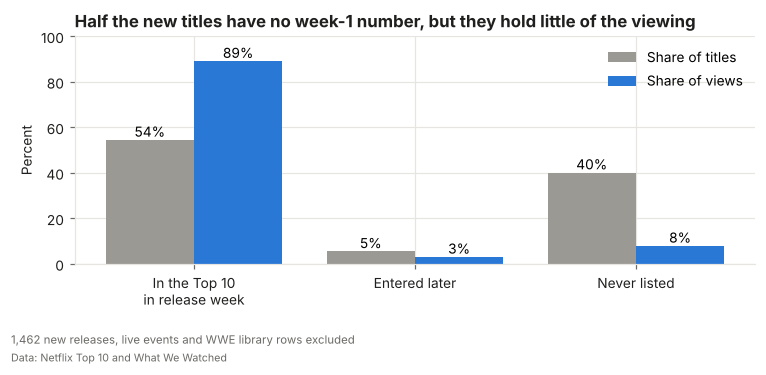

In [3]:
status_order = ["Top 10 in week 1", "Entered Top 10 later", "Never in Top 10"]
share_of_titles = programs["status"].value_counts(normalize=True).reindex(status_order)
share_of_views = (
    programs.groupby("status")["views"].sum().reindex(status_order) / programs["views"].sum()
)

figure, axis = plt.subplots(figsize=(7, 3.4))
positions = np.arange(len(status_order))
axis.bar(
    positions - 0.2, share_of_titles * 100, 0.4, color=charts.REFERENCE, label="Share of titles"
)
axis.bar(positions + 0.2, share_of_views * 100, 0.4, color=charts.ACCENT, label="Share of views")
for x, (a, b) in enumerate(zip(share_of_titles, share_of_views)):
    axis.text(x - 0.2, a * 100 + 1.5, f"{a:.0%}", ha="center", fontsize=9)
    axis.text(x + 0.2, b * 100 + 1.5, f"{b:.0%}", ha="center", fontsize=9)
axis.set_xticks(positions, ["In the Top 10\nin release week", "Entered later", "Never listed"])
axis.set_ylabel("Percent")
axis.set_ylim(0, 100)
axis.legend(loc="upper right")
axis.set_title("Half the new titles have no week-1 number, but they hold little of the viewing")
charts.finish_chart(
    figure,
    "1_coverage.png",
    note=f"{len(programs):,} new releases, live events and WWE library rows excluded",
)
plt.show()

Titles with a week-1 number are about half of the new releases and most of the viewing.

## 2. The sample

To compare like with like, the sample keeps titles that made a list in their release week and had at least 91 days left in their report window. The outcome is views over those 91 to 184 days.

In [4]:
sample = titles[(titles["status"] == "Top 10 in week 1") & (titles["days_in_window"] >= 91)].copy()
sample["multiplier"] = sample["views"] / sample["wk1_views"]
sample["after_week1"] = sample["views"] - sample["wk1_views"]
sample["log_week1"] = np.log(sample["wk1_views"])
sample["log_views"] = np.log(sample["views"])
sample["log_window_days"] = np.log(sample["days_in_window"])
sample["week1_share"] = sample["wk1_views"] / sample["views"]

release_months = sample["release"].dt.month
in_q1_or_q3 = release_months.isin([1, 2, 3, 7, 8, 9])
counts = sample["segment"].value_counts().reindex(SEGMENTS + ["Live events"])
results["sample"] = {
    "titles": len(sample),
    "by_segment": counts.to_dict(),
    "released_jan_mar_or_jul_sep": int(in_q1_or_q3.sum()),
    "staggered_series": int(sample["staggered"].sum()),
}
print(
    f"{len(sample)} titles. {in_q1_or_q3.sum()} were released in January to March or July to September."
)
print(f"{sample['staggered'].sum()} series had episodes still arriving after week 1.")
counts.to_frame("titles")

430 titles. 423 were released in January to March or July to September.
42 series had episodes still arriving after week 1.


,titles
segment,
Film / English,50
Film / Non-English,93
TV / English,121
TV / Non-English,124
Live events,42


The 91-day rule keeps only titles released early in each half-year, so the sample covers January to March and July to September. Section 6 checks the calendar result on the titles this rule drops.

Some series release episodes in batches. For them the Top 10 divides week-1 hours by the runtime out so far, while the report divides by the full season, so the two views numbers are on different scales. They are flagged as staggered and results are shown with and without them where it matters.

Live events are a separate case. They are listed here once and then left out of everything else.

In [5]:
live = sample[sample["live"]]
content = sample[~sample["live"]].copy()
results["live_events"] = {
    "titles": len(live),
    "wwe_raw_episodes": int(live["title"].str.startswith("Raw").sum()),
    "median_multiplier": live["multiplier"].median(),
    "median_week1_share_of_window": live["week1_share"].median(),
}
print(
    f"{len(live)} live events, {results['live_events']['wwe_raw_episodes']} of them WWE Raw episodes."
)
print(
    f"Median multiplier {live['multiplier'].median():.2f}. "
    f"Week 1 holds a median {live['week1_share'].median():.0%} of their window views."
)
print(f"{len(content)} titles remain.")

42 live events, 37 of them WWE Raw episodes.
Median multiplier 1.16. Week 1 holds a median 86% of their window views.
388 titles remain.


## 3. Ranking

Spearman rank correlation measures whether week 1 puts titles in the same order as the outcome (1 means the same order). The outcome includes week 1, so some agreement is built in. The second column uses views after week 1 only, which removes that overlap. Intervals are 95% bootstrap intervals over titles.

In [6]:
def spearman_on(outcome):
    return lambda table: stats.spearman(table["wk1_views"], table[outcome])


groups = {segment: content[content["segment"] == segment] for segment in SEGMENTS}
groups["All four"] = content
rows = []
for name, table in groups.items():
    row = {"group": name, "titles": len(table)}
    for outcome, label in [("views", "window"), ("after_week1", "after week 1")]:
        low, high = stats.bootstrap_interval(table, spearman_on(outcome))
        row[f"rho, {label}"] = spearman_on(outcome)(table)
        row[f"95% interval, {label}"] = stats.interval_text(low, high)
    rows.append(row)
ranking = pd.DataFrame(rows).set_index("group")
results["ranking"] = ranking.to_dict(orient="index")
ranking

,titles,"rho, window","95% interval, window","rho, after week 1","95% interval, after week 1"
group,,,,,
Film / English,50,0.95,0.88 to 0.97,0.88,0.78 to 0.93
Film / Non-English,93,0.88,0.81 to 0.93,0.78,0.67 to 0.85
TV / English,121,0.89,0.82 to 0.92,0.78,0.68 to 0.86
TV / Non-English,124,0.78,0.69 to 0.85,0.68,0.55 to 0.77
All four,388,0.87,0.84 to 0.90,0.77,0.71 to 0.82


In [7]:
gaps = {}
for first, second in [
    ("Film / English", "TV / Non-English"),
    ("Film / English", "Film / Non-English"),
    ("Film / Non-English", "TV / English"),
]:
    low, high = stats.bootstrap_difference_interval(
        groups[first], groups[second], spearman_on("views")
    )
    gaps[f"{first} minus {second}"] = {"low": low, "high": high}
    print(f"{first} minus {second}: 95% interval {low:+.2f} to {high:+.2f}")
results["ranking_gaps"] = gaps
week1_share = content.groupby("segment")["week1_share"].median().reindex(SEGMENTS)
results["week1_share_by_segment"] = week1_share.to_dict()
week1_share.to_frame("median share of window views in week 1").style.format("{:.0%}")

Film / English minus TV / Non-English: 95% interval +0.07 to +0.26


Film / English minus Film / Non-English: 95% interval -0.01 to +0.14


Film / Non-English minus TV / English: 95% interval -0.09 to +0.07


,median share of window views in week 1
segment,
Film / English,36%
Film / Non-English,33%
TV / English,32%
TV / Non-English,30%


Week 1 ranks titles well in every group. Only the gap between English films and non-English series is clearly larger than the noise. Week 1 holds about a third of the window views in every group, so the difference is not that some titles are watched faster.

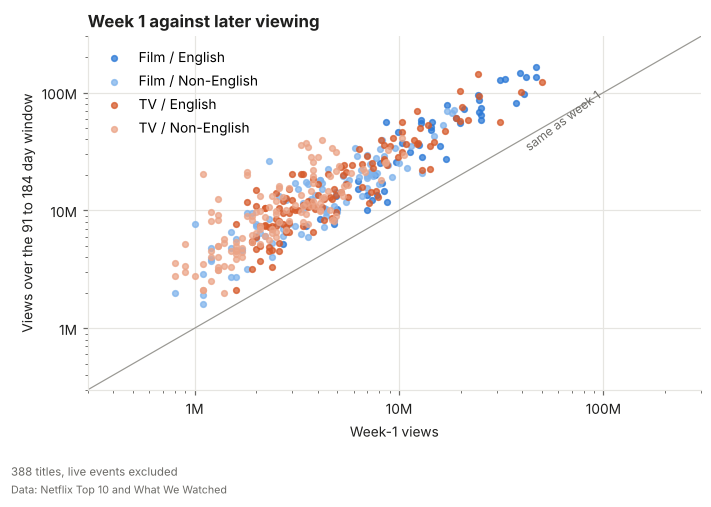

In [8]:
figure, axis = plt.subplots(figsize=(6.5, 4.6))
for segment in SEGMENTS:
    table = groups[segment]
    axis.scatter(
        table["wk1_views"], table["views"], s=14, alpha=0.75, color=COLORS[segment], label=segment
    )
limits = [3e5, 3e8]
axis.plot(limits, limits, color=charts.REFERENCE, linewidth=0.8)
axis.text(4e7, 3.2e7, "same as week 1", color=charts.MUTED, fontsize=8, rotation=37)
axis.set_xscale("log")
axis.set_yscale("log")
charts.use_views_axis(axis.xaxis)
charts.use_views_axis(axis.yaxis)
axis.set_xlim(limits)
axis.set_ylim(limits)
axis.set_xlabel("Week-1 views")
axis.set_ylabel("Views over the 91 to 184 day window")
axis.legend(loc="upper left")
axis.set_title("Week 1 against later viewing")
charts.finish_chart(figure, "2_scatter.png", note=f"{len(content)} titles, live events excluded")
plt.show()

## 4. Spread

The multiplier is window views divided by week-1 views. If it were stable, week 1 would be a good forecast. The 10th to 90th percentile range is the noise a forecast has to live with.

In [9]:
def spread(table):
    values = table["multiplier"]
    return pd.Series(
        {
            "titles": len(table),
            "p10": values.quantile(0.1),
            "median": values.median(),
            "p90": values.quantile(0.9),
            "p90 / p10": values.quantile(0.9) / values.quantile(0.1),
        }
    )


spread_all = pd.DataFrame({segment: spread(groups[segment]) for segment in SEGMENTS}).T
no_staggered = content[~content["staggered"]]
spread_clean = pd.DataFrame(
    {segment: spread(no_staggered[no_staggered["segment"] == segment]) for segment in SEGMENTS}
).T
results["spread"] = {
    "all": spread_all.to_dict(orient="index"),
    "without_staggered": spread_clean.to_dict(orient="index"),
    "median_all": content["multiplier"].median(),
}
spread_format = {
    "titles": "{:.0f}",
    "p10": "{:.2f}",
    "median": "{:.2f}",
    "p90": "{:.2f}",
    "p90 / p10": "{:.2f}",
}
print("All titles")
display(spread_all.style.format(spread_format))
print("Without staggered series")
spread_clean.style.format(spread_format)

All titles


,titles,p10,median,p90,p90 / p10
Film / English,50,1.71,2.78,4.16,2.43
Film / Non-English,93,1.91,3.05,4.76,2.49
TV / English,121,1.91,3.11,5.20,2.73
TV / Non-English,124,2.36,3.32,7.00,2.97


Without staggered series


,titles,p10,median,p90,p90 / p10
Film / English,50,1.71,2.78,4.16,2.43
Film / Non-English,93,1.91,3.05,4.76,2.49
TV / English,104,1.81,3.13,5.21,2.88
TV / Non-English,99,2.43,3.33,6.52,2.68


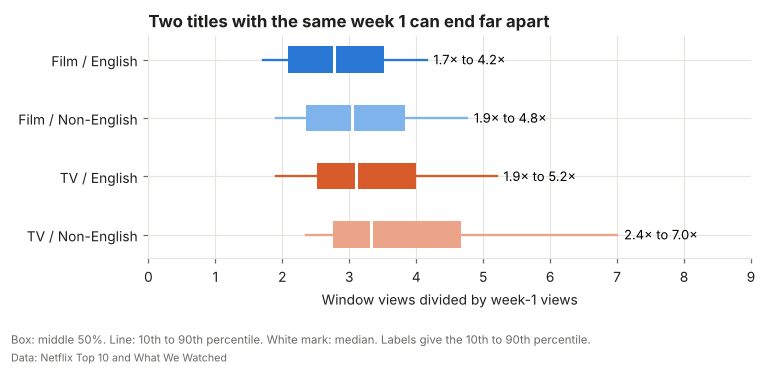

In [10]:
figure, axis = plt.subplots(figsize=(7, 3.4))
for row, segment in enumerate(SEGMENTS):
    values = groups[segment]["multiplier"]
    p10, p25, p50, p75, p90 = values.quantile([0.1, 0.25, 0.5, 0.75, 0.9])
    axis.plot([p10, p90], [row, row], color=COLORS[segment], linewidth=1.5)
    axis.barh(row, p75 - p25, left=p25, height=0.45, color=COLORS[segment])
    axis.plot([p50, p50], [row - 0.22, row + 0.22], color="white", linewidth=2)
    axis.text(p90 + 0.1, row, f"{p10:.1f}× to {p90:.1f}×", va="center", fontsize=8.5)
axis.set_yticks(range(len(SEGMENTS)), SEGMENTS)
axis.invert_yaxis()
axis.set_xlim(0, 9)
axis.set_xlabel("Window views divided by week-1 views")
axis.set_title("Two titles with the same week 1 can end far apart")
charts.finish_chart(
    figure,
    "3_multiplier.png",
    note="Box: middle 50%. Line: 10th to 90th percentile. White mark: median. Labels give the 10th to 90th percentile.",
)
plt.show()

## 5. The calendar effect

A Monday release has seven days in its first public week. A Friday release has three. The table shows the median multiplier by days live, with 95% bootstrap intervals.

In [11]:
def median_multiplier(table):
    return table["multiplier"].median()


rows = []
for days, table in content.groupby("days_live_wk1"):
    low, high = stats.bootstrap_interval(table, median_multiplier)
    rows.append(
        {
            "days live in week 1": int(days),
            "titles": len(table),
            "median multiplier": median_multiplier(table),
            "low": low,
            "high": high,
        }
    )
by_days = pd.DataFrame(rows).set_index("days live in week 1")
results["multiplier_by_days_live"] = by_days.to_dict(orient="index")
by_days.style.format(
    {"titles": "{:.0f}", "median multiplier": "{:.2f}", "low": "{:.2f}", "high": "{:.2f}"}
)

,titles,median multiplier,low,high
days live in week 1,,,,
2,6,8.77,3.15,14.76
3,118,3.75,3.49,4.07
4,102,3.36,3.16,3.66
5,97,2.76,2.64,2.88
6,48,2.09,1.91,2.38
7,17,2.13,1.68,4.77


In [12]:
FORMULA = "log_views ~ log_week1 + C(segment) + days_live_wk1 + log_window_days"


def days_effect(table, formula=FORMULA):
    """Percent change in the multiplier per extra day live, with a robust 95% interval."""
    fit = smf.ols(formula, data=table).fit(cov_type="HC3")
    low, high = fit.conf_int().loc["days_live_wk1"]
    coefficient = fit.params["days_live_wk1"]
    return {
        "titles": len(table),
        "per_day": np.exp(coefficient) - 1,
        "low": np.exp(low) - 1,
        "high": np.exp(high) - 1,
    }


within = FORMULA.replace(" + C(segment)", "")
effects = {
    "All four segments": days_effect(content),
    "Without staggered series": days_effect(no_staggered),
}
for segment in SEGMENTS:
    effects[segment] = days_effect(groups[segment], within)
for half, table in content.groupby("half"):
    effects[f"Half-year {half}"] = days_effect(table, FORMULA.replace(" + log_window_days", ""))
effects_table = pd.DataFrame(effects).T
results["days_live_effect"] = effects_table.to_dict(orient="index")
effects_table.style.format(
    {"titles": "{:.0f}", "per_day": "{:+.1%}", "low": "{:+.1%}", "high": "{:+.1%}"}
)

,titles,per_day,low,high
All four segments,388,-16.4%,-19.4%,-13.3%
Without staggered series,346,-15.7%,-18.7%,-12.6%
Film / English,50,-18.2%,-23.9%,-12.1%
Film / Non-English,93,-15.1%,-19.5%,-10.4%
TV / English,121,-11.8%,-18.1%,-5.0%
TV / Non-English,124,-20.2%,-25.6%,-14.5%
Half-year 2024H2,109,-14.1%,-21.5%,-5.9%
Half-year 2025H1,97,-18.2%,-23.0%,-13.1%
Half-year 2025H2,91,-20.6%,-26.0%,-14.9%
Half-year 2026H1,91,-12.6%,-18.7%,-6.0%


Each extra day in week 1 lowers the multiplier by about the same amount in every segment and every half-year. This is a pattern in released titles, not an experiment. Netflix chooses the release day, and the table below shows that different kinds of titles favor different days. A short first week also means the first week is mostly a weekend. The data cannot separate those two things.

In [13]:
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_mix = pd.crosstab(content["segment"], content["weekday"], normalize="index")
weekday_mix = weekday_mix.reindex(index=SEGMENTS, columns=weekday_order, fill_value=0)
results["weekday_mix"] = weekday_mix.to_dict(orient="index")
weekday_mix.style.format("{:.0%}")

weekday,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
segment,,,,,,,
Film / English,2%,20%,20%,6%,52%,0%,0%
Film / Non-English,4%,3%,20%,23%,49%,0%,0%
TV / English,10%,16%,26%,37%,11%,1%,0%
TV / Non-English,0%,13%,30%,27%,27%,4%,0%


The 91-day rule dropped titles released in April to June and October to December. For those, adding the same title's views from the next report gives an outcome of 183 to 272 days. The same regression on them is an out-of-sample check of the calendar effect.

In [14]:
dropped = titles[
    (titles["status"] == "Top 10 in week 1")
    & (titles["days_in_window"] < 91)
    & ~titles["live"]
    & titles["next_views"].notna()
].copy()
dropped["log_week1"] = np.log(dropped["wk1_views"])
dropped["log_views"] = np.log(dropped["views"] + dropped["next_views"])
dropped_effect = days_effect(dropped, "log_views ~ log_week1 + C(segment) + days_live_wk1")
results["days_live_effect_dropped_quarters"] = dropped_effect
print(
    f"{len(dropped)} titles from the dropped quarters: "
    f"{dropped_effect['per_day']:+.1%} per extra day "
    f"(95% interval {dropped_effect['low']:+.1%} to {dropped_effect['high']:+.1%})"
)

311 titles from the dropped quarters: -20.0% per extra day (95% interval -22.9% to -16.9%)


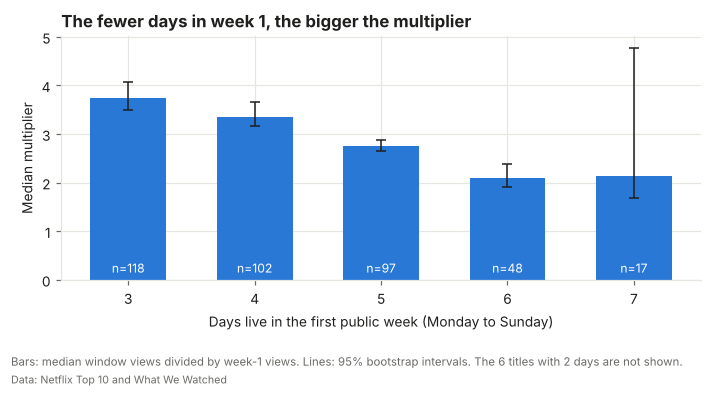

In [15]:
shown = by_days[by_days["titles"] >= 10]
figure, axis = plt.subplots(figsize=(6.5, 3.6))
axis.bar(shown.index, shown["median multiplier"], color=charts.ACCENT, width=0.6)
axis.errorbar(
    shown.index,
    shown["median multiplier"],
    yerr=[shown["median multiplier"] - shown["low"], shown["high"] - shown["median multiplier"]],
    fmt="none",
    ecolor=charts.INK,
    capsize=3,
    linewidth=1,
)
for days, row in shown.iterrows():
    axis.text(days, 0.15, f"n={row['titles']:.0f}", ha="center", color="white", fontsize=8)
axis.set_xticks(shown.index)
axis.set_xlabel("Days live in the first public week (Monday to Sunday)")
axis.set_ylabel("Median multiplier")
axis.set_title("The fewer days in week 1, the bigger the multiplier")
charts.finish_chart(
    figure,
    "4_days_live.png",
    note="Bars: median window views divided by week-1 views. Lines: 95% bootstrap intervals. The 6 titles with 2 days are not shown.",
)
plt.show()

Two series with almost the same window views, released on different days, show the effect on a single pair. One pair is an illustration, not evidence.

In [16]:
pair = titles[titles["title"].isin(["Homicide: Los Angeles", "Leanne: Season 1"])].copy()
pair["week1_per_day_live"] = pair["wk1_views"] / pair["days_live_wk1"]
pair_columns = [
    "title",
    "release",
    "weekday",
    "days_live_wk1",
    "wk1_views",
    "week1_per_day_live",
    "wk2_views",
    "views",
    "days_in_window",
]
results["pair"] = json.loads(pair[pair_columns].to_json(orient="records", date_format="iso"))
pair_view = pair[pair_columns].set_index("title").T
for row in ["wk1_views", "week1_per_day_live", "wk2_views", "views"]:
    pair_view.loc[row] = [f"{value / 1e6:.2f}M" for value in pair_view.loc[row]]
pair_view.loc["release"] = [value.date().isoformat() for value in pair_view.loc["release"]]
pair_view

title,Homicide: Los Angeles,Leanne: Season 1
release,2024-07-16,2025-07-31
weekday,Tuesday,Thursday
days_live_wk1,6.00,4.00
wk1_views,4.30M,2.70M
week1_per_day_live,0.72M,0.68M
wk2_views,2.40M,2.80M
views,12.50M,12.00M
days_in_window,169,154


## 6. Does a days-live correction help?

First, ranking. Week 1 is scaled to a seven-day week with the per-day coefficient, and the coefficient is always fit on the other three half-years, so no title helps correct itself. Intervals on the gain are paired bootstrap intervals.

In [17]:
content["week1_adjusted"] = np.nan
adjust_formula = "log_views ~ log_week1 + C(segment) + days_live_wk1"
for half in content["half"].unique():
    held_out = content["half"] == half
    coefficient = smf.ols(adjust_formula, data=content[~held_out]).fit().params["days_live_wk1"]
    scale = np.exp(coefficient * (content.loc[held_out, "days_live_wk1"] - 7))
    content.loc[held_out, "week1_adjusted"] = content.loc[held_out, "wk1_views"] * scale


def adjustment_gain(table):
    return stats.spearman(table["week1_adjusted"], table["views"]) - stats.spearman(
        table["wk1_views"], table["views"]
    )


rows = []
for name, table in [(segment, content[content["segment"] == segment]) for segment in SEGMENTS] + [
    ("All four", content)
]:
    low, high = stats.bootstrap_interval(table, adjustment_gain)
    rows.append(
        {
            "group": name,
            "raw week 1": stats.spearman(table["wk1_views"], table["views"]),
            "adjusted": stats.spearman(table["week1_adjusted"], table["views"]),
            "gain": adjustment_gain(table),
            "low": low,
            "high": high,
        }
    )
ranking_gain = pd.DataFrame(rows).set_index("group")
results["ranking_after_adjustment"] = ranking_gain.to_dict(orient="index")
ranking_gain

,raw week 1,adjusted,gain,low,high
group,,,,,
Film / English,0.95,0.97,0.02,0.00,0.06
Film / Non-English,0.88,0.92,0.04,0.01,0.06
TV / English,0.89,0.89,0.01,-0.03,0.04
TV / Non-English,0.78,0.85,0.07,0.03,0.11
All four,0.87,0.90,0.03,0.01,0.04


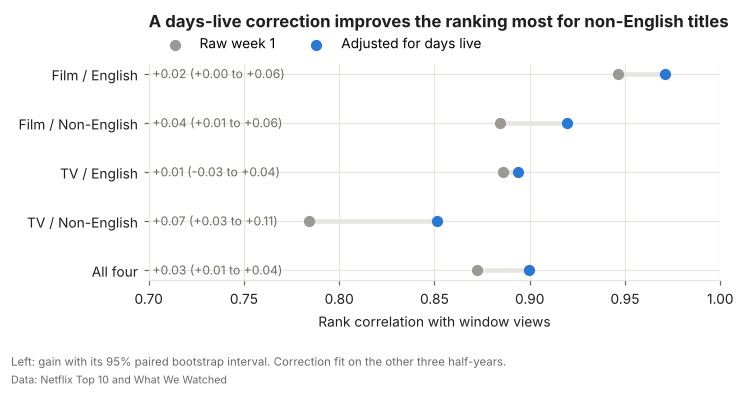

In [18]:
figure, axis = plt.subplots(figsize=(6.8, 3.6))
positions = np.arange(len(ranking_gain))
axis.scatter(
    ranking_gain["raw week 1"],
    positions,
    color=charts.REFERENCE,
    s=40,
    label="Raw week 1",
    zorder=3,
)
axis.scatter(
    ranking_gain["adjusted"],
    positions,
    color=charts.ACCENT,
    s=40,
    label="Adjusted for days live",
    zorder=3,
)
for position, (_, row) in zip(positions, ranking_gain.iterrows()):
    axis.plot(
        [row["raw week 1"], row["adjusted"]],
        [position, position],
        color=charts.GRID,
        linewidth=3,
        zorder=2,
    )
    axis.text(
        0.702,
        position,
        f"{row['gain']:+.2f} ({row['low']:+.2f} to {row['high']:+.2f})",
        va="center",
        ha="left",
        fontsize=8,
        color=charts.MUTED,
    )
axis.set_yticks(positions, ranking_gain.index)
axis.invert_yaxis()
axis.set_xlim(0.7, 1.0)
axis.set_xlabel("Rank correlation with window views")
axis.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2)
axis.set_title("A days-live correction improves the ranking most for non-English titles", pad=24)
charts.finish_chart(
    figure,
    "5_ranking_adjusted.png",
    note="Left: gain with its 95% paired bootstrap interval. Correction fit on the other three half-years.",
)
plt.show()

Next, forecasting. Each half-year is held out in turn, the forecasts are fit on the other three, and all titles are scored once. The four forecasts are week 1 times one multiplier, times a multiplier per segment, times a multiplier per number of days live, and a regression with segment, days live and window length. The error is the absolute percent error, and the mean absolute log error is shown too because percent errors punish over-forecasts more than under-forecasts.

In [19]:
METHODS = {
    "one multiplier": "pred_one",
    "by segment": "pred_segment",
    "by days live": "pred_days",
    "regression": "pred_regression",
}


def forecasts(train, test):
    """Every multiplier and the regression are fit on the training titles only."""
    test = test.copy()
    test["pred_one"] = test["wk1_views"] * train["multiplier"].median()
    test["pred_segment"] = test["wk1_views"] * test["segment"].map(
        train.groupby("segment")["multiplier"].median()
    )
    test["pred_days"] = test["wk1_views"] * test["days_live_wk1"].map(
        train.groupby("days_live_wk1")["multiplier"].median()
    )
    test["pred_regression"] = np.exp(smf.ols(FORMULA, data=train).fit().predict(test))
    return test


scored = pd.concat(
    [
        forecasts(content[content["half"] != half], content[content["half"] == half])
        for half in sorted(content["half"].unique())
    ]
)
for column in METHODS.values():
    scored[f"error_{column}"] = (scored[column] - scored["views"]).abs() / scored["views"]


def median_error(column):
    return lambda table: table[f"error_{column}"].median()


rows = []
for name, column in METHODS.items():
    low, high = stats.bootstrap_interval(scored, median_error(column))
    rows.append(
        {
            "forecast": name,
            "median error": scored[f"error_{column}"].median(),
            "low": low,
            "high": high,
            "within 25%": (scored[f"error_{column}"] <= 0.25).mean(),
            "mean abs log error": np.abs(np.log(scored[column] / scored["views"])).mean(),
        }
    )
forecast_table = pd.DataFrame(rows).set_index("forecast")
results["forecast"] = forecast_table.to_dict(orient="index")
forecast_table.style.format(
    {
        "median error": "{:.1%}",
        "low": "{:.1%}",
        "high": "{:.1%}",
        "within 25%": "{:.0%}",
        "mean abs log error": "{:.3f}",
    }
)

,median error,low,high,within 25%,mean abs log error
forecast,,,,,
one multiplier,23.6%,20.1%,27.0%,53%,0.308
by segment,24.3%,20.2%,28.1%,52%,0.305
by days live,22.0%,18.9%,24.4%,57%,0.284
regression,20.7%,18.4%,22.6%,59%,0.257


In [20]:
differences = {}
for name in ["by segment", "by days live", "regression"]:
    column = METHODS[name]
    gap = lambda table, c=column: table["error_pred_one"].median() - table[f"error_{c}"].median()
    low, high = stats.bootstrap_interval(scored, gap)
    differences[f"one multiplier minus {name}"] = {"points": gap(scored), "low": low, "high": high}
    print(
        f"one multiplier minus {name}: {gap(scored) * 100:+.1f} points (95% interval {low * 100:+.1f} to {high * 100:+.1f})"
    )
results["forecast_differences"] = differences

one multiplier minus by segment: -0.7 points (95% interval -2.0 to +1.6)


one multiplier minus by days live: +1.6 points (95% interval -1.4 to +5.1)


one multiplier minus regression: +2.9 points (95% interval -0.1 to +6.1)


A point forecast should come with a range. The 10th and 90th percentiles of the regression's held-out errors give an 80% range around any forecast.

In [21]:
log_errors = np.log(scored["views"] / scored["pred_regression"])
low_factor, high_factor = np.exp(log_errors.quantile([0.1, 0.9]))
results["forecast_80pct_range"] = {
    "low_factor": low_factor,
    "high_factor": high_factor,
    "example_32m": [32e6 * low_factor, 32e6 * high_factor],
}
print(
    f"80% of titles ended between {low_factor:.2f} and {high_factor:.2f} times their forecast. "
    f"For a 32 million forecast: {32 * low_factor:.0f} to {32 * high_factor:.0f} million."
)

80% of titles ended between 0.68 and 1.51 times their forecast. For a 32 million forecast: 22 to 48 million.


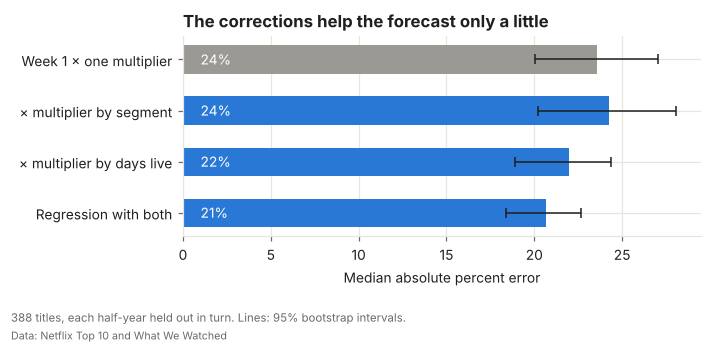

In [22]:
figure, axis = plt.subplots(figsize=(6.5, 3.2))
positions = np.arange(len(forecast_table))
axis.barh(
    positions,
    forecast_table["median error"] * 100,
    color=[charts.REFERENCE] + [charts.ACCENT] * 3,
    height=0.55,
)
axis.errorbar(
    forecast_table["median error"] * 100,
    positions,
    xerr=[
        (forecast_table["median error"] - forecast_table["low"]) * 100,
        (forecast_table["high"] - forecast_table["median error"]) * 100,
    ],
    fmt="none",
    ecolor=charts.INK,
    capsize=3,
    linewidth=1,
)
for position, value in zip(positions, forecast_table["median error"]):
    axis.text(1, position, f"{value:.0%}", va="center", color="white", fontsize=9)
axis.set_yticks(
    positions,
    [
        "Week 1 × one multiplier",
        "× multiplier by segment",
        "× multiplier by days live",
        "Regression with both",
    ],
)
axis.invert_yaxis()
axis.set_xlabel("Median absolute percent error")
axis.set_title("The corrections help the forecast only a little")
charts.finish_chart(
    figure,
    "6_forecast_error.png",
    note=f"{len(scored)} titles, each half-year held out in turn. Lines: 95% bootstrap intervals.",
)
plt.show()

The corrections help the ranking more than the forecast. None of them beats the single multiplier by more than the noise. The regression comes closest, by about 3 points.

## 7. Follow-up: how much comes after the window?

For titles from the first three half-years, the same title can be looked up in the next report. That shows how much the following six months added.

In [23]:
followed = content[content["next_views"].notna()].copy()
followed["added_share"] = followed["next_views"] / followed["views"]
window_bins = pd.cut(
    followed["days_in_window"], [90, 121, 152, 184], labels=["91-121", "122-152", "153-184"]
)
results["follow_up"] = {
    "titles": len(followed),
    "of_eligible": int((content["half"] != "2026H1").sum()),
    "median_added": followed["added_share"].median(),
    "p10_added": followed["added_share"].quantile(0.1),
    "p90_added": followed["added_share"].quantile(0.9),
    "median_added_by_window": followed.groupby(window_bins, observed=True)["added_share"]
    .median()
    .to_dict(),
    "spearman_window_vs_window_plus_next": stats.spearman(
        followed["views"], followed["views"] + followed["next_views"]
    ),
}
print(
    f"{len(followed)} titles found in the next report. The next six months added a median "
    f"{results['follow_up']['median_added']:.0%} (10th to 90th percentile "
    f"{results['follow_up']['p10_added']:.0%} to {results['follow_up']['p90_added']:.0%})."
)
followed.groupby(window_bins, observed=True)["added_share"].median().to_frame(
    "median added"
).style.format("{:.0%}")

297 titles found in the next report. The next six months added a median 14% (10th to 90th percentile 8% to 24%).


,median added
days_in_window,
91-121,17%
122-152,13%
153-184,12%


## 8. What week 1 misses

Among releases with at least 91 days in the window (live events and WWE library rows excluded), take the top quarter by window views. How many were not on a list in their release week? The check is repeated on hours, because hours favor long series.

In [24]:
pool = programs[programs["days_in_window"] >= 91]


def misses(measure):
    cutoff = pool[measure].quantile(0.75)
    top = pool[pool[measure] >= cutoff]
    missed = top[top["status"] != "Top 10 in week 1"]
    low, high = stats.wilson_interval(len(missed), len(top))
    return {
        "pool": len(pool),
        "top_quarter": len(top),
        "missed": len(missed),
        "share": len(missed) / len(top),
        "low": low,
        "high": high,
        "missed_weekdays": missed["weekday"].value_counts().to_dict(),
    }


results["misses"] = {"by_views": misses("views"), "by_hours": misses("hours")}
pd.DataFrame(results["misses"]).T[
    ["pool", "top_quarter", "missed", "share", "low", "high", "missed_weekdays"]
]

,pool,top_quarter,missed,share,low,high,missed_weekdays
by_views,674,170,5,0.03,0.01,0.07,"{'Friday': 3, 'Monday': 1, 'Saturday': 1}"
by_hours,674,169,16,0.09,0.06,0.15,"{'Friday': 5, 'Saturday': 5, 'Wednesday': 4, '..."


## 9. Limits

- Weekly views exist only for titles on the global lists. Titles that charted only in their home country are missing.
- The outcome window runs 91 to 184 days, depending on the release date. The regression controls for it, and the follow-up check shows how much comes later.
- Release day is chosen by Netflix, so the calendar effect is an observed pattern, not a randomized one.
- Views are the only public outcome. They say nothing about cost, completion or retention.
- Netflix rounds hours and views. Small titles carry the largest rounding error.
- This is an exploratory analysis. Hypotheses were not written down before running it.

In [25]:
def to_plain(value):
    """Make numpy numbers and keys JSON friendly."""
    if isinstance(value, dict):
        return {str(key): to_plain(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [to_plain(item) for item in value]
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating, float)):
        return None if np.isnan(value) else round(float(value), 4)
    return value


with open("results.json", "w") as file:
    json.dump(to_plain(results), file, indent=1)
print("results.json written")

results.json written
